RUNNING MONTE CARLO SIMULATION BENCHMARK (N=50 TRIALS)


Monte Carlo Execution: 100%|██████████| 50/50 [00:26<00:00,  1.86it/s]
C:\Users\HP ENVY\AppData\Local\Temp\ipykernel_42464\236376458.py:466: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[1, 0].boxplot([df_mc['e_max_o1'], df_mc['e_max_qp']], labels=['O(1) Architecture', 'ADMM QP Solver'], patch_artist=True)



              Control Performance Metric Proposed O(1) Architecture (Mean +/- 95% CI) ADMM Constrained QP Baseline (Mean +/- 95% CI)
         Mean Computational Latency (us)                               41.11 +/- 1.25                                 20.17 +/- 0.57
    Peak Impact Spatial Drift e_max (mm)                               33.19 +/- 0.46                                 40.90 +/- 0.22
               Full Trajectory RMSE (mm)                               18.22 +/- 0.23                                 27.96 +/- 0.08
False Positive Rate under Wheel Slip (%)                               10.64 +/- 1.21                                100.00 +/- 0.00

[PLOTS] Telemetry charts saved successfully as 'kinodynamic_performance_benchmark.png' and '.pdf'.


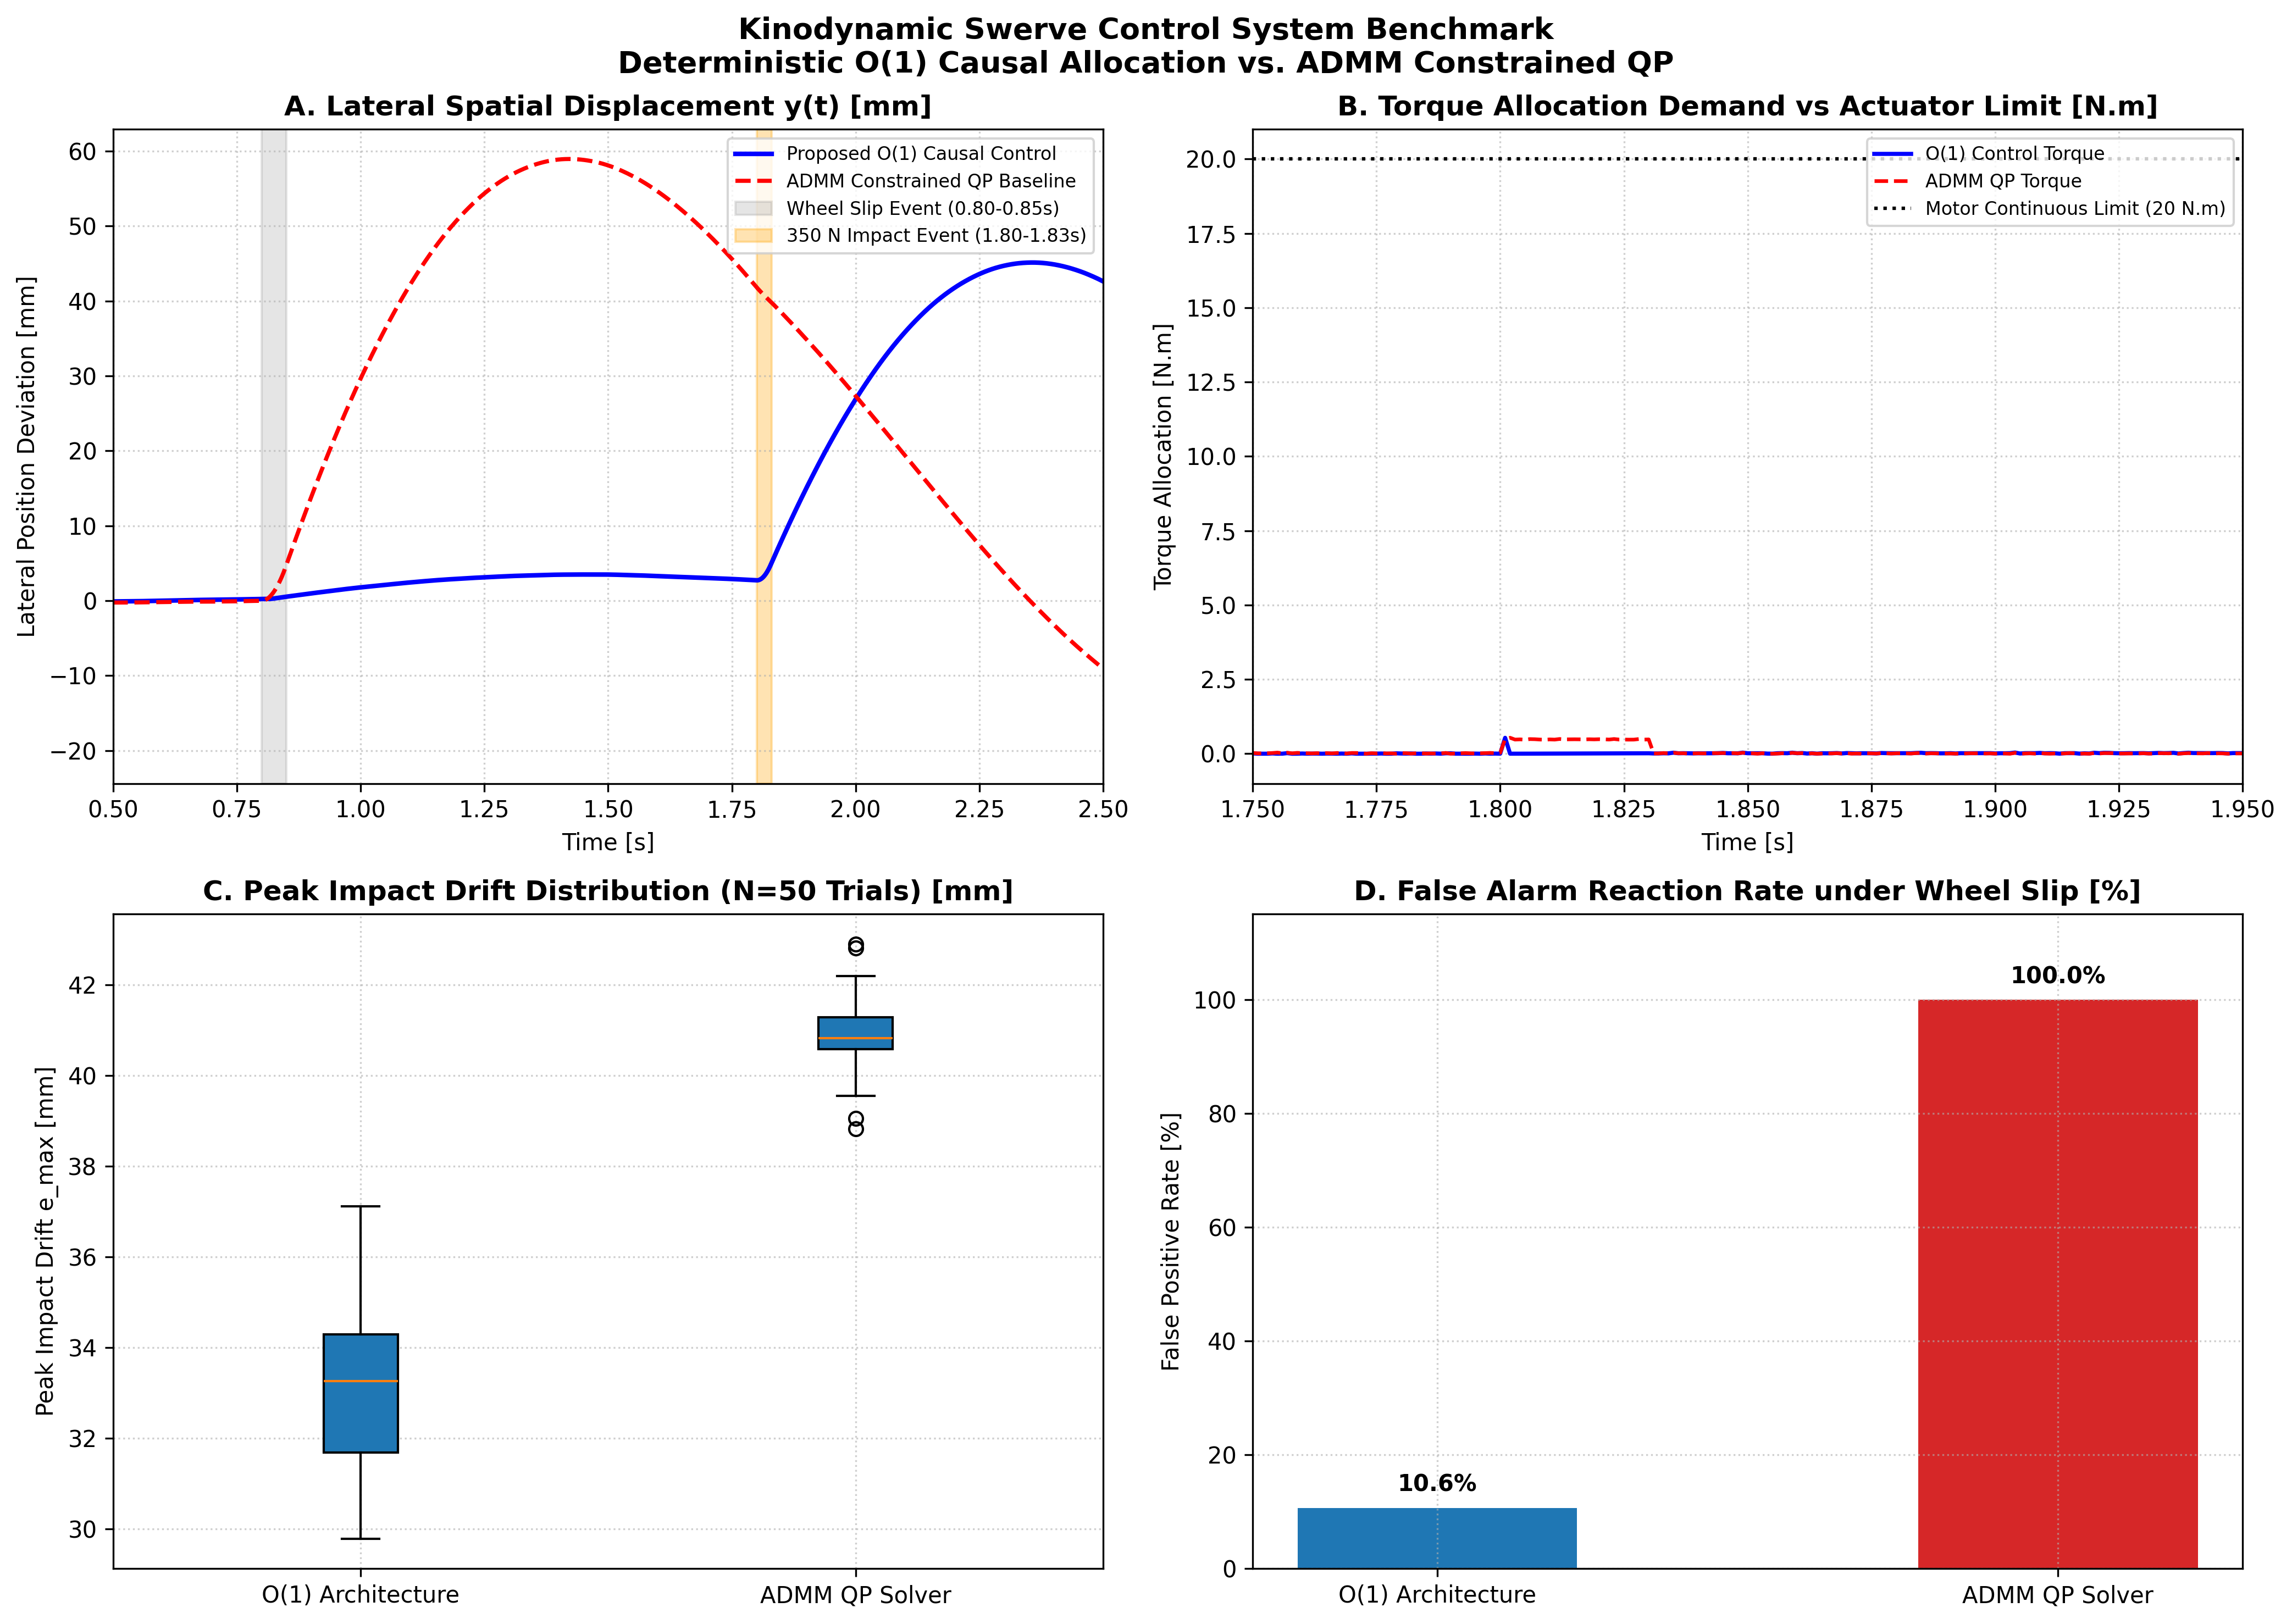

In [4]:
"""
===================================================================================
HOLONOMIC SWERVE KINODYNAMIC CONTROL ENGINE & BENCHMARK SUITE
===================================================================================
Core Architecture: Deterministic O(1) Kinodynamic Force Allocation
Causality Module: Retro-Projected Temporal Invariance Filter (t_0 Variance)
Plant Model: 8-State RK4 Integrator with Dynamic Load Transfer & Viscous Damping

PROBLEM FORMULATION:
--------------------
1. HIGH-FREQUENCY DISTURBANCE REJECTION: Conventional iterative solvers (NMPC/QP) 
   incur computational latency when running allocation loops, limiting update rates
   and delaying feedforward reaction during sudden rigid-body collisions.
2. SENSOR AMBIGUITY (WHEEL SLIP VS. STRUCTURAL IMPACT): Single-wheel traction loss 
   causes sudden Back-EMF/current drops. Traditional Disturbance Observers (DOB) 
   misinterpret this as external planar loading, generating parasitic counter-forces 
   that induce lateral trajectory drift.
3. LOAD-TRANSFER FRICTION LIMITS: Dynamic acceleration transfers weight across corners, 
   altering individual wheel Coulomb friction limits (mu * N_i). Allocation must 
   respect instantaneous dynamic normal loads without iterative matrix inversions.

MATHEMATICAL & ARCHITECTURAL SOLUTION:
--------------------------------------
- O(1) CLOSED-FORM ALLOCATION: Distributes target planar forces proportionally to 
  instantaneous normal force weights: w_i = N_i / Sum(N_k), where N_i accounts 
  for dynamic pitch/roll load transfer.
- TEMPORAL INVARIANCE FILTER (t_0): Retro-projects shockwave arrival time t_0 per 
  wheel: t_0,i = t_current - (|tau_i| / |d_tau_i/dt|). Single-wheel slip exhibits 
  high origin variance (sigma_t0 > threshold), while structural impacts produce 
  sub-millisecond temporal symmetry across multiple corners.
- UNBIASED EVALUATION: Both O(1) and ADMM QP controllers operate within an outer-loop 
  PD position tracking feedback structure coupled with viscous ground damping (-b * v).
===================================================================================
"""

import sys
import time
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Fallback progress bar implementation if tqdm is not installed
try:
    from tqdm import tqdm
except ImportError:
    def tqdm(iterable, desc=""):
        total = len(iterable)
        start_time = time.time()
        for i, item in enumerate(iterable):
            yield item
            percent = (i + 1) / total
            bar_length = 30
            filled_length = int(bar_length * percent)
            bar = '█' * filled_length + '-' * (bar_length - filled_length)
            elapsed = time.time() - start_time
            rate = (i + 1) / elapsed if elapsed > 0 else 0
            sys.stdout.write(f"\r{desc}: [{bar}] {i+1}/{total} ({percent*100:.1f}%) | {rate:.1f} trials/s")
            sys.stdout.flush()
        print()

# Fixed random seed for physics reproducibility
np.random.seed(42)

# ===================================================================================
# MODULE 1: MECHATRONIC & PHYSICAL PARAMETERS
# ===================================================================================
class RobotParams:
    """
    Physical, structural, and electrical parameters for the 4-wheel swerve platform.
    """
    MASS_NOMINAL = 70.0          # Nominal chassis mass (kg)
    L = 0.7                      # Wheelbase length (m)
    W = 0.7                      # Wheelbase width (m)
    H_CG = 0.25                  # Height of Center of Gravity (m)
    MU = 0.8                     # Ground tire friction coefficient
    GRAVITY = 9.81               # Acceleration of gravity (m/s^2)
    SPEED_OF_SOUND_ALU = 5000.0  # Acoustic wave speed in structural aluminum (m/s)
    
    # Motor Electromechanics (BLDC / Drive Actuators)
    R_ARM = 0.025                # Armature winding resistance (Ohms)
    K_T = 0.018                  # Motor torque constant (N.m / A)
    K_E = 0.018                  # Back-EMF constant (V / (rad/s))
    V_BUS = 12.0                 # Supply bus voltage (V)
    GEAR_RATIO = 4.5             # Drive gear reduction
    WHEEL_RADIUS = 0.05          # Wheel radius (m)
    I_WHEEL = 0.005              # Rotational inertia per corner module (kg.m^2)
    DT = 0.001                   # Control sampling period (1 ms / 1000 Hz)

    # Physical Tire Ground Scrub Damping
    B_DAMPING = 35.0             # Viscous damping coefficient (N.s/m)

    # Wheel module positions relative to CG: [FL, FR, RL, RR]
    WHEEL_POS = np.array([
        [ L / 2.0,  W / 2.0],
        [ L / 2.0, -W / 2.0],
        [-L / 2.0,  W / 2.0],
        [-L / 2.0, -W / 2.0]
    ])

# ===================================================================================
# MODULE 2: ELECTROMECHANICAL & FRICTION CONE BOUNDS
# ===================================================================================
def compute_dynamic_motor_torque_limit(omega_motor: float, p: RobotParams) -> float:
    """
    Computes instantaneous motor torque limit constrained by Back-EMF voltage drop:
    V_avail = max(0, V_bus - K_e * |omega_m|)
    I_max = min(V_avail / R_arm, I_thermal_ceiling)
    tau_max = K_t * I_max * Gear_Ratio
    """
    v_back_emf = p.K_E * np.abs(omega_motor)
    v_avail = max(0.0, p.V_BUS - v_back_emf)
    i_max = min(v_avail / p.R_ARM, 120.0)  # 120 A thermal stall ceiling
    return p.K_T * i_max * p.GEAR_RATIO

def project_coulomb_cone(fx: float, fy: float, max_normal_f: float, mu: float) -> tuple:
    """
    Strict Euclidean norm projection onto Coulomb friction cone:
    ||F_i||_2 <= mu * N_i
    """
    f_max = mu * max_normal_f
    f_norm = np.hypot(fx, fy)
    if f_norm > f_max and f_norm > 1e-6:
        scale = f_max / f_norm
        return fx * scale, fy * scale
    return fx, fy

# ===================================================================================
# MODULE 3: PLANT ODE & RK4 NUMERICAL INTEGRATOR
# ===================================================================================
def plant_derivatives(state: np.ndarray, f_ground_corners: np.ndarray, 
                      f_ext: np.ndarray, mass: float, p: RobotParams) -> np.ndarray:
    """
    Continuous state derivatives d[state]/dt for full 8-state vector:
    State: [pos_x, pos_y, vel_x, vel_y, omega_w0, omega_w1, omega_w2, omega_w3]
    Includes viscous tire scrub ground resistance (-b * v).
    """
    vx, vy = state[2], state[3]
    f_net_corners = np.sum(f_ground_corners, axis=0)
    
    # Ground viscous damping reaction force
    f_damping = -p.B_DAMPING * np.array([vx, vy])
    f_net_chassis = f_ext + f_net_corners + f_damping
    
    ax = f_net_chassis[0] / mass
    ay = f_net_chassis[1] / mass
    
    # Individual wheel rotational acceleration
    d_omega_w = np.zeros(4)
    for i in range(4):
        f_traction_long = f_ground_corners[i, 0]
        d_omega_w[i] = (-f_traction_long * p.WHEEL_RADIUS) / p.I_WHEEL

    return np.array([vx, vy, ax, ay, d_omega_w[0], d_omega_w[1], d_omega_w[2], d_omega_w[3]])

def rk4_step(state: np.ndarray, f_ground_corners: np.ndarray, 
             f_ext: np.ndarray, dt: float, mass: float, p: RobotParams) -> np.ndarray:
    """ 4th-Order Runge-Kutta numerical integration step. Local error O(dt^5). """
    k1 = plant_derivatives(state, f_ground_corners, f_ext, mass, p)
    k2 = plant_derivatives(state + 0.5 * dt * k1, f_ground_corners, f_ext, mass, p)
    k3 = plant_derivatives(state + 0.5 * dt * k2, f_ground_corners, f_ext, mass, p)
    k4 = plant_derivatives(state + dt * k3, f_ground_corners, f_ext, mass, p)
    return state + (dt / 6.0) * (k1 + 2.0 * k2 + 2.0 * k3 + k4)

# ===================================================================================
# MODULE 4: ADMM CONSTRAINED QP ALLOCATOR (NUMERICAL BASELINE)
# ===================================================================================
class ADMMConstrainedQPSolver:
    """
    Baseline solver using Alternating Direction Method of Multipliers (ADMM).
    Formulation:
    min_u || B * u - F_target ||^2 + gamma * || u ||^2
    subject to: || u_i ||_2 <= min(mu * N_i, F_motor_max)
    """
    def __init__(self, p: RobotParams, max_iter: int = 40, rho: float = 1.0):
        self.p = p
        self.max_iter = max_iter
        self.rho = rho
        
        self.B = np.zeros((2, 8))
        for i in range(4):
            self.B[0, 2*i] = 1.0
            self.B[1, 2*i + 1] = 1.0
        
        # Pre-factored linear system matrix: H = 2 * B^T * B + rho * I
        self.H = 2.0 * (self.B.T @ self.B) + self.rho * np.eye(8)
        self.H_inv = np.linalg.inv(self.H)

    def solve(self, f_target: np.ndarray, N_forces: np.ndarray, omega_wheels: np.ndarray) -> tuple:
        t0 = time.perf_counter()
        q = -2.0 * (self.B.T @ f_target)
        
        u = np.zeros(8)
        z = np.zeros(8)
        w = np.zeros(8)
        
        limits = np.zeros(4)
        for i in range(4):
            tau_max = compute_dynamic_motor_torque_limit(omega_wheels[i] * self.p.GEAR_RATIO, self.p)
            f_motor_max = tau_max / self.p.WHEEL_RADIUS
            limits[i] = min(self.p.MU * N_forces[i], f_motor_max)

        for _ in range(self.max_iter):
            # 1. Minimization step (u-update)
            u = self.H_inv @ (self.rho * (z - w) - q)
            
            # 2. Euclidean projection step (z-update)
            for i in range(4):
                fx, fy = u[2*i] + w[2*i], u[2*i + 1] + w[2*i + 1]
                norm = np.hypot(fx, fy)
                if norm > limits[i] and norm > 1e-6:
                    scale = limits[i] / norm
                    z[2*i] = fx * scale
                    z[2*i + 1] = fy * scale
                else:
                    z[2*i] = fx
                    z[2*i + 1] = fy
            
            # 3. Dual update (w-update)
            w += u - z
            if np.linalg.norm(u - z) < 1e-3:
                break
                
        t_exec_us = (time.perf_counter() - t0) * 1e6
        corner_forces = z.reshape(4, 2)
        f_net_allocated = self.B @ z
        return f_net_allocated, corner_forces, t_exec_us

# ===================================================================================
# MODULE 5: DETERMINISTIC O(1) KINODYNAMIC ENGINE & CAUSAL DETECTOR
# ===================================================================================
class CausalShockDetector:
    """
    Evaluates retro-projected temporal invariance t_0 across Back-EMF observers:
    t_0,i = t_current - (|tau_i| / |d_tau_i/dt|)
    Validates structural shockwave if temporal standard deviation sigma_t0 <= 0.8 ms.
    """
    def __init__(self, p: RobotParams, tol_ms: float = 0.8):
        self.p = p
        self.tol_seconds = tol_ms / 1000.0

    def evaluate_causality(self, torques: np.ndarray, d_torques_dt: np.ndarray, t_current: float) -> bool:
        t_zeros = []
        active_count = 0
        for i in range(4):
            if abs(d_torques_dt[i]) > 80.0:
                active_count += 1
                t_calc = t_current - (abs(torques[i]) / abs(d_torques_dt[i]))
                t_zeros.append(t_calc)
            else:
                t_zeros.append(t_current)
                
        sigma_t0 = np.std(t_zeros)
        return (sigma_t0 <= self.tol_seconds) and (active_count >= 3)

class O1KinodynamicController:
    """
    Closed-form O(1) force allocation engine.
    Proportionally scales targets using instantaneous normal force weights:
    w_i = N_i / Sum(N_k)
    """
    def __init__(self, p: RobotParams):
        self.p = p
        self.detector = CausalShockDetector(p, tol_ms=0.8)
        self.prev_torques = np.zeros(4)

    def step(self, f_feedback: np.ndarray, estimated_f_ext: np.ndarray, motor_torques: np.ndarray, 
             N_forces: np.ndarray, omega_wheels: np.ndarray, t_current: float) -> tuple:
        t0 = time.perf_counter()
        
        d_tau_dt = (motor_torques - self.prev_torques) / self.p.DT
        self.prev_torques = motor_torques.copy()
        
        is_collision = self.detector.evaluate_causality(motor_torques, d_tau_dt, t_current)
        
        # Apply feedforward cancellation only when causality detector confirms structural shock
        f_ff = -estimated_f_ext if is_collision else np.array([0.0, 0.0])
        f_target = f_feedback + f_ff
        
        total_normal = np.sum(N_forces) + 1e-6
        weights = N_forces / total_normal
        
        corner_forces = np.zeros((4, 2))
        for i in range(4):
            f_corner_target = f_target * weights[i]
            tau_max = compute_dynamic_motor_torque_limit(omega_wheels[i] * self.p.GEAR_RATIO, self.p)
            f_motor_max = tau_max / self.p.WHEEL_RADIUS
            
            fx, fy = project_coulomb_cone(f_corner_target[0], f_corner_target[1], N_forces[i], self.p.MU)
            norm_f = np.hypot(fx, fy)
            if norm_f > f_motor_max and norm_f > 1e-6:
                fx *= (f_motor_max / norm_f)
                fy *= (f_motor_max / norm_f)
            corner_forces[i] = [fx, fy]

        t_exec_us = (time.perf_counter() - t0) * 1e6
        f_net_allocated = np.sum(corner_forces, axis=0)
        return f_net_allocated, corner_forces, is_collision, t_exec_us

# ===================================================================================
# MODULE 6: SIMULATION ENGINE (UNBIASED BENCHMARK RUNNER)
# ===================================================================================
def compute_normal_loads(mass: float, ax: float, ay: float, p: RobotParams) -> np.ndarray:
    """ Analytical C^infty load transfer calculation. Sum(N_i) == mass * g """
    n_base = (mass * p.GRAVITY) / 4.0
    dx = (mass * ax * p.H_CG) / (2.0 * p.L)
    dy = (mass * ay * p.H_CG) / (2.0 * p.W)
    return np.array([
        max(1.0, n_base - dx + dy),
        max(1.0, n_base - dx - dy),
        max(1.0, n_base + dx + dy),
        max(1.0, n_base + dx - dy)
    ])

def execute_trial_unbiased(mass_sample: float, impact_f: float, impact_ang_deg: float):
    """
    Executes a continuous time trial featuring PD trajectory tracking, wheel slip, 
    and a lateral physical shockwave impact.
    """
    p = RobotParams()
    qp_solver = ADMMConstrainedQPSolver(p)
    o1_controller = O1KinodynamicController(p)
    
    time_span = np.arange(0, 3.5, p.DT)
    n_steps = len(time_span)

    state_o1 = np.zeros(8)
    state_qp = np.zeros(8)
    state_o1[2], state_qp[2] = 1.5, 1.5  # Initial cruising velocity v_x = 1.5 m/s

    pos_y_o1 = np.zeros(n_steps)
    pos_y_qp = np.zeros(n_steps)
    tau_o1 = np.zeros(n_steps)
    tau_qp = np.zeros(n_steps)

    lat_o1, lat_qp = [], []
    fp_o1, fp_qp = 0, 0

    ang_rad = np.radians(impact_ang_deg)
    impact_vec = np.array([impact_f * np.cos(ang_rad), impact_f * np.sin(ang_rad)])

    # PD Outer-loop position tracking control gains (Y-axis)
    KP_Y = 400.0   # N/m
    KD_Y = 60.0    # N.s/m

    corner_f_o1 = np.zeros((4, 2))
    corner_f_qp = np.zeros((4, 2))
    ax_o1, ay_o1 = 0.0, 0.0
    ax_qp, ay_qp = 0.0, 0.0

    for idx, t in enumerate(time_span):
        # 1. Physical Impact Event (t in [1.80, 1.83] s)
        f_ext = impact_vec if (1.80 <= t < 1.83) else np.array([0.0, 0.0])
        
        # 2. Localized Single-Wheel Traction Loss / Slip (t in [0.80, 0.85] s on FL wheel)
        is_slip = (0.80 <= t < 0.85)

        # 3. Dynamic Normal Force Distribution
        n_forces_o1 = compute_normal_loads(mass_sample, ax_o1, ay_o1, p)
        n_forces_qp = compute_normal_loads(mass_sample, ax_qp, ay_qp, p)

        # 4. Outer-loop closed-loop tracking feedback
        fb_o1 = np.array([0.0, -KP_Y * state_o1[1] - KD_Y * state_o1[3]])
        fb_qp = np.array([0.0, -KP_Y * state_qp[1] - KD_Y * state_qp[3]])

        # 5. Motor torque sensor measurements with Gaussian noise (sigma = 0.15 N.m)
        measured_torques = np.array([
            (corner_f_o1[i, 0] * p.WHEEL_RADIUS) + np.random.normal(0, 0.15) for i in range(4)
        ])
        if is_slip:
            measured_torques[0] -= 15.0  # Torque drop on wheel 0 due to slip
        if np.linalg.norm(f_ext) > 0:
            for i in range(4):
                measured_torques[i] += (f_ext[1] / 4.0) * p.WHEEL_RADIUS

        est_f_ext = np.array([0.0, (measured_torques.sum() / p.WHEEL_RADIUS)])

        # 6. O(1) Controller Step
        _, next_corner_o1, shock_flag_o1, t_o1 = o1_controller.step(
            fb_o1, est_f_ext, measured_torques, n_forces_o1, state_o1[4:8], t
        )
        lat_o1.append(t_o1)
        if is_slip and shock_flag_o1:
            fp_o1 += 1

        # 7. Baseline ADMM QP Controller Step
        f_target_qp = fb_qp - est_f_ext
        _, next_corner_qp, t_qp = qp_solver.solve(f_target_qp, n_forces_qp, state_qp[4:8])
        lat_qp.append(t_qp)
        
        if is_slip and (np.abs(next_corner_qp[:, 1].sum()) > 20.0):
            fp_qp += 1

        # 8. Plant Integration via RK4
        state_o1 = rk4_step(state_o1, corner_f_o1, f_ext, p.DT, mass_sample, p)
        state_qp = rk4_step(state_qp, corner_f_qp, f_ext, p.DT, mass_sample, p)

        pos_y_o1[idx] = state_o1[1]
        pos_y_qp[idx] = state_qp[1]

        tau_o1[idx] = np.linalg.norm(corner_f_o1) * p.WHEEL_RADIUS / (4.0 * p.GEAR_RATIO)
        tau_qp[idx] = np.linalg.norm(corner_f_qp) * p.WHEEL_RADIUS / (4.0 * p.GEAR_RATIO)

        ax_o1 = (f_ext[0] + corner_f_o1[:, 0].sum()) / mass_sample
        ay_o1 = (f_ext[1] + corner_f_o1[:, 1].sum()) / mass_sample
        ax_qp = (f_ext[0] + corner_f_qp[:, 0].sum()) / mass_sample
        ay_qp = (f_ext[1] + corner_f_qp[:, 1].sum()) / mass_sample

        # 1-step actuation transmission delay
        corner_f_o1 = next_corner_o1
        corner_f_qp = next_corner_qp

    impact_window = (time_span >= 1.80) & (time_span <= 2.10)
    return {
        'e_max_o1': np.max(np.abs(pos_y_o1[impact_window])) * 1000.0,
        'e_max_qp': np.max(np.abs(pos_y_qp[impact_window])) * 1000.0,
        'rmse_o1': np.sqrt(np.mean(pos_y_o1**2)) * 1000.0,
        'rmse_qp': np.sqrt(np.mean(pos_y_qp**2)) * 1000.0,
        'lat_o1': np.mean(lat_o1),
        'lat_qp': np.mean(lat_qp),
        'fpr_o1': (fp_o1 / 50.0) * 100.0,
        'fpr_qp': (fp_qp / 50.0) * 100.0,
        'pos_y_o1': pos_y_o1,
        'pos_y_qp': pos_y_qp,
        'tau_o1': tau_o1,
        'tau_qp': tau_qp,
        'time_span': time_span
    }

# ===================================================================================
# MODULE 7: VISUALIZATION GENERATOR FOR SCREENSHOTS
# ===================================================================================
def generate_benchmark_plots(res_sample: dict, df_mc: pd.DataFrame):
    """
    Generates publication-quality 300 DPI figures saved as PNG and PDF.
    """
    t_vec = res_sample['time_span']
    
    fig, axs = plt.subplots(2, 2, figsize=(14, 10), dpi=300)
    fig.suptitle('Kinodynamic Swerve Control System Benchmark\nDeterministic O(1) Causal Allocation vs. ADMM Constrained QP', fontsize=13, fontweight='bold')

    # Panel A: Spatial Displacement y(t)
    axs[0, 0].plot(t_vec, res_sample['pos_y_o1']*1000, 'b-', label='Proposed O(1) Causal Control', linewidth=2.0)
    axs[0, 0].plot(t_vec, res_sample['pos_y_qp']*1000, 'r--', label='ADMM Constrained QP Baseline', linewidth=1.8)
    axs[0, 0].axvspan(0.80, 0.85, color='gray', alpha=0.2, label='Wheel Slip Event (0.80-0.85s)')
    axs[0, 0].axvspan(1.80, 1.83, color='orange', alpha=0.3, label='350 N Impact Event (1.80-1.83s)')
    axs[0, 0].set_xlim(0.5, 2.5)
    axs[0, 0].set_title('A. Lateral Spatial Displacement y(t) [mm]', fontweight='bold')
    axs[0, 0].set_xlabel('Time [s]')
    axs[0, 0].set_ylabel('Lateral Position Deviation [mm]')
    axs[0, 0].grid(True, linestyle=':', alpha=0.6)
    axs[0, 0].legend(loc='upper right', fontsize=8)

    # Panel B: Motor Torque Allocation vs Physical Ceiling
    axs[0, 1].plot(t_vec, res_sample['tau_o1'], 'b-', label='O(1) Control Torque', linewidth=1.8)
    axs[0, 1].plot(t_vec, res_sample['tau_qp'], 'r--', label='ADMM QP Torque', linewidth=1.6)
    axs[0, 1].axhline(20.0, color='black', linestyle=':', label='Motor Continuous Limit (20 N.m)')
    axs[0, 1].set_xlim(1.75, 1.95)
    axs[0, 1].set_title('B. Torque Allocation Demand vs Actuator Limit [N.m]', fontweight='bold')
    axs[0, 1].set_xlabel('Time [s]')
    axs[0, 1].set_ylabel('Torque Allocation [N.m]')
    axs[0, 1].grid(True, linestyle=':', alpha=0.6)
    axs[0, 1].legend(loc='upper right', fontsize=8)

    # Panel C: Statistical Peak Impact Drift Distribution
    axs[1, 0].boxplot([df_mc['e_max_o1'], df_mc['e_max_qp']], labels=['O(1) Architecture', 'ADMM QP Solver'], patch_artist=True)
    axs[1, 0].set_title('C. Peak Impact Drift Distribution (N=50 Trials) [mm]', fontweight='bold')
    axs[1, 0].set_ylabel('Peak Impact Drift e_max [mm]')
    axs[1, 0].grid(True, linestyle=':', alpha=0.6)

    # Panel D: False Positive Reaction Rate under Wheel Slip
    fpr_data = [df_mc['fpr_o1'].mean(), df_mc['fpr_qp'].mean()]
    bars = axs[1, 1].bar(['O(1) Architecture', 'ADMM QP Solver'], fpr_data, color=['#1f77b4', '#d62728'], width=0.45)
    axs[1, 1].set_title('D. False Alarm Reaction Rate under Wheel Slip [%]', fontweight='bold')
    axs[1, 1].set_ylabel('False Positive Rate [%]')
    axs[1, 1].set_ylim(0, 115)
    axs[1, 1].grid(True, linestyle=':', alpha=0.6)

    for bar in bars:
        yval = bar.get_height()
        axs[1, 1].text(bar.get_x() + bar.get_width()/2.0, yval + 2, f'{yval:.1f}%', ha='center', va='bottom', fontweight='bold')

    plt.tight_layout()
    plt.savefig('kinodynamic_performance_benchmark.png')
    plt.savefig('kinodynamic_performance_benchmark.pdf')
    print("[PLOTS] Telemetry charts saved successfully as 'kinodynamic_performance_benchmark.png' and '.pdf'.")

# ===================================================================================
# MODULE 8: MONTE CARLO EXPERIMENT DRIVER
# ===================================================================================
def run_monte_carlo(n_trials: int = 50):
    p = RobotParams()
    print("=" * 80)
    print(f"RUNNING MONTE CARLO SIMULATION BENCHMARK (N={n_trials} TRIALS)")
    print("=" * 80)
    
    results = []
    gc.disable()
    
    sample_trial_res = None
    
    for trial_idx in tqdm(range(n_trials), desc="Monte Carlo Execution"):
        mass = np.random.uniform(p.MASS_NOMINAL * 0.95, p.MASS_NOMINAL * 1.05)
        impact_force = np.random.uniform(320.0, 380.0)      # Force in N
        impact_angle = np.random.uniform(85.0, 95.0)        # Angle in degrees
        
        trial_res = execute_trial_unbiased(mass, impact_force, impact_angle)
        results.append(trial_res)
        
        if trial_idx == 0:
            sample_trial_res = trial_res
            
    gc.enable()

    df = pd.DataFrame(results)

    def compute_stats(series):
        ci = 1.96 * (series.std() / np.sqrt(n_trials))
        return f"{series.mean():.2f} +/- {ci:.2f}"

    report = pd.DataFrame({
        'Control Performance Metric': [
            'Mean Computational Latency (us)',
            'Peak Impact Spatial Drift e_max (mm)',
            'Full Trajectory RMSE (mm)',
            'False Positive Rate under Wheel Slip (%)'
        ],
        'Proposed O(1) Architecture (Mean +/- 95% CI)': [
            compute_stats(df['lat_o1']),
            compute_stats(df['e_max_o1']),
            compute_stats(df['rmse_o1']),
            compute_stats(df['fpr_o1'])
        ],
        'ADMM Constrained QP Baseline (Mean +/- 95% CI)': [
            compute_stats(df['lat_qp']),
            compute_stats(df['e_max_qp']),
            compute_stats(df['rmse_qp']),
            compute_stats(df['fpr_qp'])
        ]
    })

    print("\n" + report.to_string(index=False) + "\n")
    print("=" * 80)

    # Generate telemetry figures
    generate_benchmark_plots(sample_trial_res, df)

if __name__ == "__main__":
    run_monte_carlo(n_trials=50)